Some experiments was performed on the dataset in this notebook.

The experiments are:
1. EDA
2. Data Processing
3. Model training
4. Model evaluation

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from imblearn.over_sampling import RandomOverSampler
import warnings

sns.set_theme(style="whitegrid")
warnings.filterwarnings("ignore")

# Loading Data

In [2]:
df = pd.read_csv("data.csv")
df.head()

,id,Gender,Age,Driving_License,Region_Code,Previously_Insured,Vehicle_Age,Vehicle_Damage,Annual_Premium,Policy_Sales_Channel,Vintage,Response
0,1,Male,44,1,28.0,0,> 2 Years,Yes,40454.0,26.0,217,1
1,2,Male,76,1,3.0,0,1-2 Year,No,33536.0,26.0,183,0
2,3,Male,47,1,28.0,0,> 2 Years,Yes,38294.0,26.0,27,1
3,4,Male,21,1,11.0,1,< 1 Year,No,28619.0,152.0,203,0
4,5,Female,29,1,41.0,1,< 1 Year,No,27496.0,152.0,39,0


# EDA

## General Insighting

In [3]:
df.shape

(381109, 12)

In [4]:
df.isnull().sum()

id                      0
Gender                  0
Age                     0
Driving_License         0
Region_Code             0
Previously_Insured      0
Vehicle_Age             0
Vehicle_Damage          0
Annual_Premium          0
Policy_Sales_Channel    0
Vintage                 0
Response                0
dtype: int64

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 381109 entries, 0 to 381108
Data columns (total 12 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   id                    381109 non-null  int64  
 1   Gender                381109 non-null  str    
 2   Age                   381109 non-null  int64  
 3   Driving_License       381109 non-null  int64  
 4   Region_Code           381109 non-null  float64
 5   Previously_Insured    381109 non-null  int64  
 6   Vehicle_Age           381109 non-null  str    
 7   Vehicle_Damage        381109 non-null  str    
 8   Annual_Premium        381109 non-null  float64
 9   Policy_Sales_Channel  381109 non-null  float64
 10  Vintage               381109 non-null  int64  
 11  Response              381109 non-null  int64  
dtypes: float64(3), int64(6), str(3)
memory usage: 34.9 MB


In [6]:
df.describe()

,id,Age,Driving_License,Region_Code,Previously_Insured,Annual_Premium,Policy_Sales_Channel,Vintage,Response
count,381109.000000,381109.000000,381109.000000,381109.000000,381109.000000,381109.000000,381109.000000,381109.000000,381109.000000
mean,190555.000000,38.822584,0.997869,26.388807,0.458210,30564.389581,112.034295,154.347397,0.122563
std,110016.836208,15.511611,0.046110,13.229888,0.498251,17213.155057,54.203995,83.671304,0.327936
min,1.000000,20.000000,0.000000,0.000000,0.000000,2630.000000,1.000000,10.000000,0.000000
25%,95278.000000,25.000000,1.000000,15.000000,0.000000,24405.000000,29.000000,82.000000,0.000000
50%,190555.000000,36.000000,1.000000,28.000000,0.000000,31669.000000,133.000000,154.000000,0.000000
75%,285832.000000,49.000000,1.000000,35.000000,1.000000,39400.000000,152.000000,227.000000,0.000000
max,381109.000000,85.000000,1.000000,52.000000,1.000000,540165.000000,163.000000,299.000000,1.000000


## Comparitive Analysis

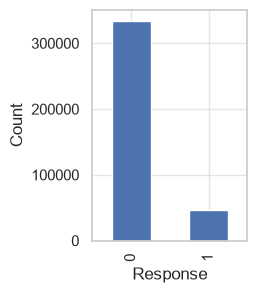

In [7]:
response_val_cnt = df['Response'].value_counts()

plt.figure(figsize=(2,3))
response_val_cnt.plot(kind='bar')
plt.xlabel("Response")
plt.ylabel("Count")
plt.show()

<Axes: >

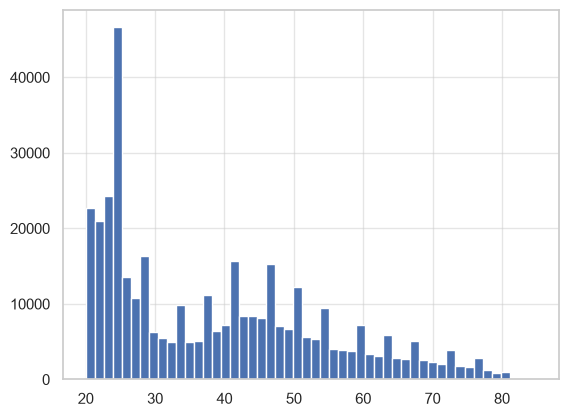

In [8]:
df['Age'].hist(bins=50)

### Response based on Annula_Premium and Age

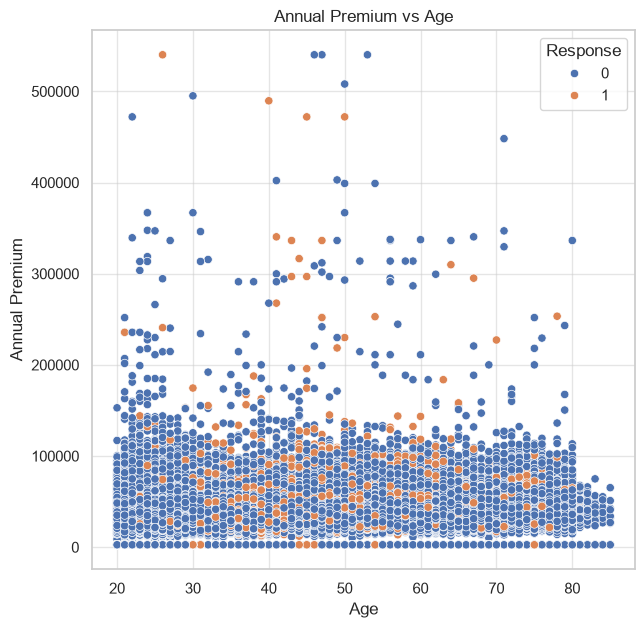

In [9]:
plt.figure(figsize=(7,7))
sns.scatterplot(x='Age', y='Annual_Premium', data=df, hue='Response')
plt.title("Annual Premium vs Age")
plt.xlabel("Age")
plt.ylabel("Annual Premium")
plt.show()

### Gender Response Comparison

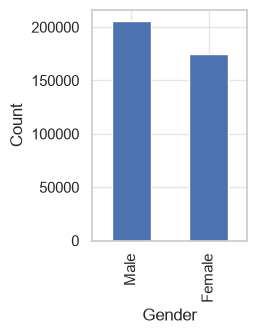

In [10]:
gender_val_cnt = df['Gender'].value_counts()
plt.figure(figsize=(2,3))
gender_val_cnt.plot(kind='bar')
plt.xlabel("Gender")
plt.ylabel("Count")
plt.show()

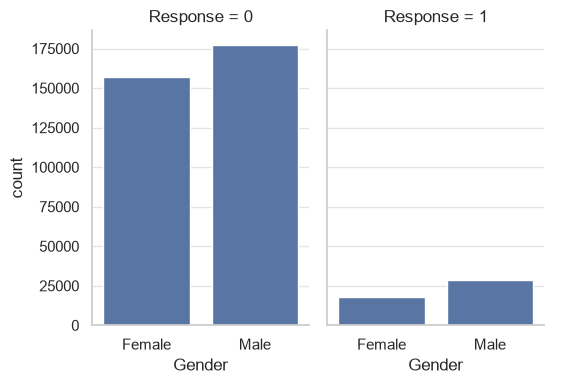

In [11]:
data = df.groupby(['Gender','Response'])['id'].count().to_frame().rename(columns={'id':'count'}).reset_index()

g = sns.catplot(x="Gender", y="count",col="Response", data=data, kind="bar", height=4, aspect=.7);

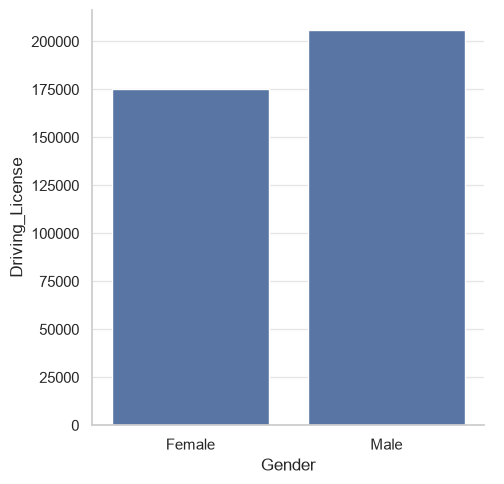

In [12]:
data = df.groupby(['Gender'])['Driving_License'].count().to_frame().reset_index()
sns.catplot(x='Gender', y='Driving_License', data=data, kind="bar");

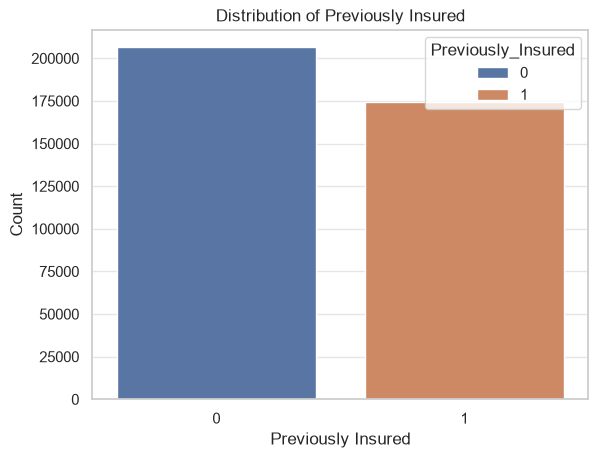

In [13]:
sns.countplot(x="Previously_Insured", data=df, hue="Previously_Insured")
plt.title("Distribution of Previously Insured")
plt.xlabel("Previously Insured")
plt.ylabel("Count")
plt.show()

### Analyzing Vehicle Age effects

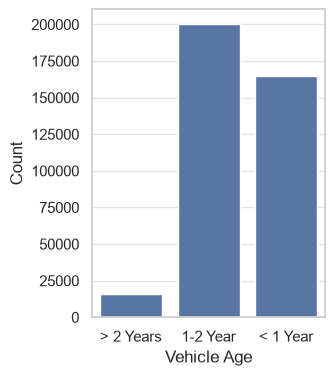

In [14]:
plt.figure(figsize=(3,4))
sns.countplot(x='Vehicle_Age', data=df)
plt.xlabel("Vehicle Age")
plt.ylabel("Count")
plt.show()

In [15]:
data = df.groupby(['Vehicle_Age', 'Response'])['id'].count().to_frame().reset_index()
print(data)

  Vehicle_Age  Response      id
0    1-2 Year         0  165510
1    1-2 Year         1   34806
2    < 1 Year         0  157584
3    < 1 Year         1    7202
4   > 2 Years         0   11305
5   > 2 Years         1    4702


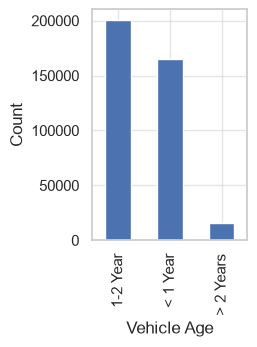

In [16]:
vehicle_age_count = df['Vehicle_Age'].value_counts()

plt.figure(figsize=(2,3))
vehicle_age_count.plot(kind='bar')
plt.xlabel("Vehicle Age")
plt.ylabel("Count")
plt.show()

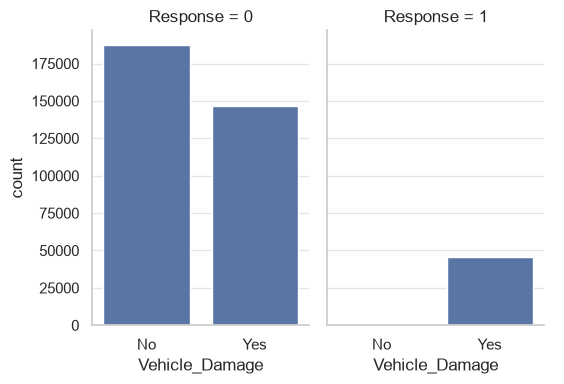

In [17]:
data = df.groupby(['Vehicle_Damage','Response'])['id'].count().to_frame().rename(columns={'id':'count'}).reset_index()
g = sns.catplot(x="Vehicle_Damage", y="count",col="Response", data=data, kind="bar", height=4, aspect=.7);

#### Note: This feature is very decisive, cause we can clearly see that a vehicle with zero damage has no Insurance Response.